# Experiment 11: Convection–Diffusion Transport in Prescribed Velocity Fields


**Aim:** compare scalar (temperature) transport in a forced flat-plate flow, a forced channel flow and a natural-convection *surrogate* (recirculating) velocity field.



### Environment and plotting helpers

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

FIG = "figures"
os.makedirs(FIG, exist_ok=True)

def show(fig, name, dpi=150):
    """Save a figure to ./figures and display it inline."""
    path = f"{FIG}/{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=path))

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
pd.set_option("display.width", 200)
print("environment ready (numpy, pandas, matplotlib only)")

environment ready (numpy, pandas, matplotlib only)


In [2]:
import numpy as np

DOMAIN = {"forced_plate": (5.0, 1.0), "forced_pipe": (5.0, 1.0), "natural_plate": (1.0, 1.0)}
LABEL = {"forced_plate": "Forced flat plate", "forced_pipe": "Forced channel", "natural_plate": "Natural-convection surrogate"}


def build_case(name, nx=121, ny=61, Pe=200.0):
    """Grid, prescribed velocity (u, v) and initial temperature for one case."""
    L, H = DOMAIN[name]
    x1, y1 = np.linspace(0.0, L, nx), np.linspace(0.0, H, ny)
    X, Y = np.meshgrid(x1, y1)
    dx, dy = x1[1] - x1[0], y1[1] - y1[0]
    T, v = np.zeros((ny, nx)), np.zeros((ny, nx))
    if name == "forced_plate":            # boundary-layer-like profile u = tanh(y/delta(x))
        delta = 0.035 + 0.22 * np.sqrt(np.maximum(X, dx) / L)
        u = np.tanh(Y / np.maximum(delta, 1e-12))
    elif name == "forced_pipe":           # parabolic channel profile, mean velocity 1
        u = 6.0 * (Y / H) * (1.0 - Y / H)
    else:                                 # divergence-free recirculating cell (stream function)
        u = -(1.0 / H) * np.sin(np.pi * X / L) * np.cos(np.pi * Y / H)
        v = (1.0 / L) * np.cos(np.pi * X / L) * np.sin(np.pi * Y / H)
        T = 1.0 - X / L                   # linear initial temperature
    return dict(name=name, L=L, H=H, nx=nx, ny=ny, X=X, Y=Y, dx=dx, dy=dy,
                u=u, v=v, T=T, Pe=Pe, alpha=1.0 / Pe)

In [3]:
def apply_bc(c):
    T, X, L = c["T"], c["X"], c["L"]
    if c["name"] == "forced_plate":       # inlet 0, top 0, bottom heated for x >= 0.25 L, outflow zero-gradient
        T[:, 0] = 0.0
        T[-1, :] = 0.0
        T[0, :] = np.where(X[0, :] >= 0.25 * L, 1.0, 0.0)
        T[1:-1, -1] = T[1:-1, -2]
    elif c["name"] == "forced_pipe":      # inlet 0, both walls 1, outflow zero-gradient
        T[:, 0] = 0.0
        T[0, :] = 1.0
        T[-1, :] = 1.0
        T[1:-1, -1] = T[1:-1, -2]
    else:                                 # hot left wall, cold right wall, adiabatic top and bottom
        T[:, 0] = 1.0
        T[:, -1] = 0.0
        T[0, 1:-1] = T[1, 1:-1]
        T[-1, 1:-1] = T[-2, 1:-1]

In [4]:
def upwind(T, vel, d, axis):
    """First-order upwind derivative at interior nodes (axis 1 = x, axis 0 = y)."""
    if axis == 1:
        back, fwd = (T[1:-1, 1:-1] - T[1:-1, :-2]) / d, (T[1:-1, 2:] - T[1:-1, 1:-1]) / d
    else:
        back, fwd = (T[1:-1, 1:-1] - T[:-2, 1:-1]) / d, (T[2:, 1:-1] - T[1:-1, 1:-1]) / d
    return np.where(vel[1:-1, 1:-1] >= 0.0, back, fwd)


def laplacian(T, dx, dy):
    return ((T[1:-1, 2:] - 2.0 * T[1:-1, 1:-1] + T[1:-1, :-2]) / dx**2
            + (T[2:, 1:-1] - 2.0 * T[1:-1, 1:-1] + T[:-2, 1:-1]) / dy**2)


def time_step(c):
    """Explicit stability-limited time step (convective 0.35, diffusive 0.20)."""
    max_u, max_v = max(np.abs(c["u"]).max(), 1e-12), max(np.abs(c["v"]).max(), 1e-12)
    return min(0.35 * min(c["dx"] / max_u, c["dy"] / max_v),
               0.20 * min(c["dx"]**2, c["dy"]**2) / c["alpha"])

In [5]:
def outlet_or_mean(c):
    """Outlet temperature weighted by u (forced) or interior mean (natural)."""
    T = c["T"]
    if c["name"] == "natural_plate":
        return float(np.mean(T[1:-1, 1:-1]))
    w = np.maximum(c["u"][1:-1, -1], 0.0)
    return float(np.mean(T[1:-1, -1])) if w.sum() < 1e-14 else float(np.average(T[1:-1, -1], weights=w))


def wall_flux(c):
    """Mean wall temperature gradient -dT/dn (one-sided first-order difference)."""
    T = c["T"]
    if c["name"] == "forced_plate":
        heated = c["X"][0, 1:-1] >= 0.25 * c["L"]
        return float(np.mean((-(T[1, 1:-1] - T[0, 1:-1]) / c["dy"])[heated]))
    if c["name"] == "forced_pipe":
        bottom, top = np.abs((T[0, 1:-1] - T[1, 1:-1]) / c["dy"]), np.abs((T[-1, 1:-1] - T[-2, 1:-1]) / c["dy"])
        return float(np.mean(np.concatenate((bottom, top))))
    return float(np.mean(-(T[1:-1, 1] - T[1:-1, 0]) / c["dx"]))

In [6]:
def solve(c, iterations=3000, tol=1e-9, min_iter=100, clip=True):
    """Explicit pseudo-time marching of  dT/dt + u.grad(T) = (1/Pe) laplacian(T)."""
    apply_bc(c)
    dt = time_step(c)
    hist = []
    for it in range(1, iterations + 1):
        old = c["T"].copy()
        conv = c["u"][1:-1, 1:-1] * upwind(old, c["u"], c["dx"], 1) + c["v"][1:-1, 1:-1] * upwind(old, c["v"], c["dy"], 0)
        new = old[1:-1, 1:-1] + dt * (-conv + c["alpha"] * laplacian(old, c["dx"], c["dy"]))
        c["T"][1:-1, 1:-1] = np.clip(new, -0.05, 1.05) if clip else new
        apply_bc(c)
        res = float(np.sqrt(np.mean((c["T"][1:-1, 1:-1] - old[1:-1, 1:-1]) ** 2)))
        hist.append((it, res, outlet_or_mean(c), wall_flux(c)))
        if not np.all(np.isfinite(c["T"])):
            raise FloatingPointError("non-finite temperature")
        if res < tol and it > min_iter:
            break
    c.update(dt=dt, history=np.array(hist), iterations=it, residual=res, converged=bool(res < tol and it > min_iter))
    return c

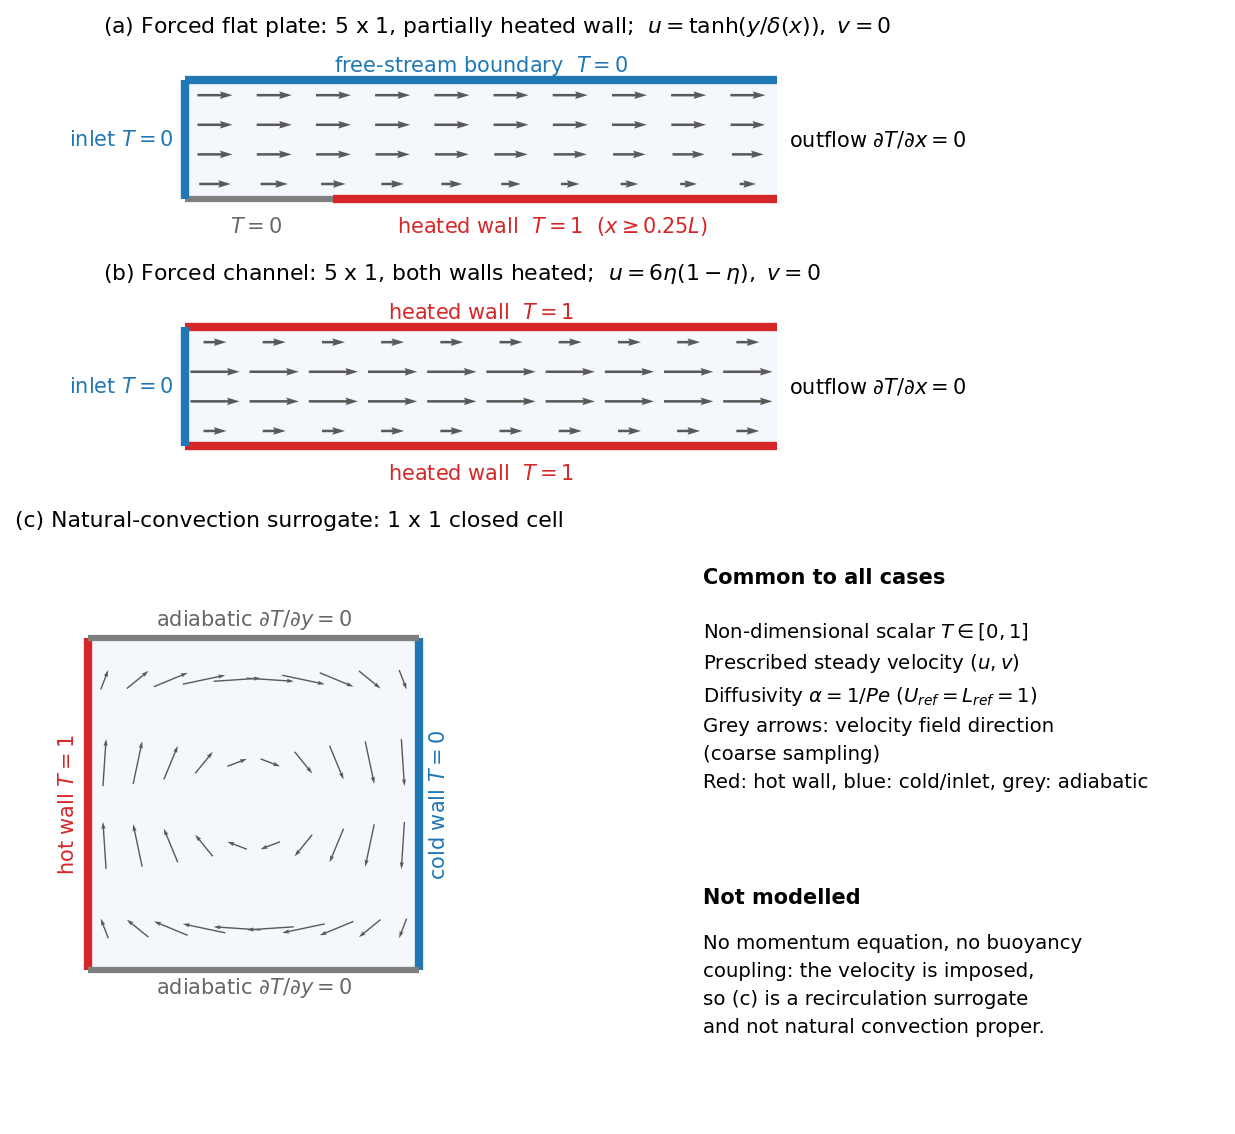

In [7]:
from matplotlib.patches import Rectangle

def draw_domain(ax, name, title):
    c = build_case(name, 21, 9)
    L, H = c["L"], c["H"]
    ax.add_patch(Rectangle((0, 0), L, H, fc="#f4f7fb", ec="none"))
    # velocity arrows (coarse sampling of the prescribed field)
    sx, sy = (slice(1, None, 2), slice(1, -1, 2)) if name != "natural_plate" else (slice(1, -1, 2), slice(1, -1, 2))
    ax.quiver(c["X"][sy, sx], c["Y"][sy, sx], c["u"][sy, sx], c["v"][sy, sx], color="0.35", width=0.003, pivot="mid", scale=24 if name != "natural_plate" else 9)
    bc = {"hot": ("#d62728", 4), "cold": ("#1f77b4", 4), "ins": ("0.5", 3)}
    def seg(xs, ys, kind): ax.plot(xs, ys, color=bc[kind][0], lw=bc[kind][1], solid_capstyle="butt")
    if name == "forced_plate":
        seg([0, 0.25 * L], [0, 0], "ins"); seg([0.25 * L, L], [0, 0], "hot"); seg([0, L], [H, H], "cold"); seg([0, 0], [0, H], "cold")
        ax.text(0.62 * L, -0.28 * H, r"heated wall  $T=1$  ($x\geq0.25L$)", color="#d62728", ha="center")
        ax.text(0.12 * L, -0.28 * H, r"$T=0$", color="0.4", ha="center")
        ax.text(0.5 * L, 1.08 * H, r"free-stream boundary  $T=0$", color="#1f77b4", ha="center")
        ax.text(-0.02 * L, 0.5 * H, r"inlet $T=0$", color="#1f77b4", ha="right", va="center")
        ax.text(1.02 * L, 0.5 * H, r"outflow $\partial T/\partial x=0$", ha="left", va="center")
    elif name == "forced_pipe":
        seg([0, L], [0, 0], "hot"); seg([0, L], [H, H], "hot"); seg([0, 0], [0, H], "cold")
        ax.text(0.5 * L, -0.28 * H, r"heated wall  $T=1$", color="#d62728", ha="center")
        ax.text(0.5 * L, 1.08 * H, r"heated wall  $T=1$", color="#d62728", ha="center")
        ax.text(-0.02 * L, 0.5 * H, r"inlet $T=0$", color="#1f77b4", ha="right", va="center")
        ax.text(1.02 * L, 0.5 * H, r"outflow $\partial T/\partial x=0$", ha="left", va="center")
    else:
        seg([0, 0], [0, H], "hot"); seg([L, L], [0, H], "cold"); seg([0, L], [0, 0], "ins"); seg([0, L], [H, H], "ins")
        ax.text(-0.03 * L, 0.5 * H, r"hot wall $T=1$", color="#d62728", ha="right", va="center", rotation=90)
        ax.text(1.03 * L, 0.5 * H, r"cold wall $T=0$", color="#1f77b4", ha="left", va="center", rotation=90)
        ax.text(0.5 * L, -0.07 * H, r"adiabatic $\partial T/\partial y=0$", color="0.4", ha="center")
        ax.text(0.5 * L, 1.04 * H, r"adiabatic $\partial T/\partial y=0$", color="0.4", ha="center")
    ax.set_title(title, loc="left", fontsize=10.5)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-0.12 * L - 0.1, 1.28 * L if name != "natural_plate" else 1.18 * L)
    ax.set_ylim(-0.45 * H, 1.3 * H)

fig = plt.figure(figsize=(12, 9.3))
gs = fig.add_gridspec(3, 2, width_ratios=[2.2, 1.35], height_ratios=[1, 1, 2.8], hspace=0.12, wspace=0.05)
draw_domain(fig.add_subplot(gs[0, :]), "forced_plate", r"(a) Forced flat plate: 5 x 1, partially heated wall;  $u=\tanh(y/\delta(x)),\ v=0$")
draw_domain(fig.add_subplot(gs[1, :]), "forced_pipe", r"(b) Forced channel: 5 x 1, both walls heated;  $u=6\eta(1-\eta),\ v=0$")
draw_domain(fig.add_subplot(gs[2, 0]), "natural_plate", "(c) Natural-convection surrogate: 1 x 1 closed cell")
ax = fig.add_subplot(gs[2, 1]); ax.axis("off")
ax.text(0, 0.95, "Common to all cases", fontweight="bold", va="top")
ax.text(0, 0.86, "Non-dimensional scalar $T\\in[0,1]$\nPrescribed steady velocity $(u,v)$\nDiffusivity $\\alpha=1/Pe$ ($U_{ref}=L_{ref}=1$)\nGrey arrows: velocity field direction\n(coarse sampling)\nRed: hot wall, blue: cold/inlet, grey: adiabatic", va="top", fontsize=9.5, linespacing=1.6)
ax.text(0, 0.40, "Not modelled", fontweight="bold", va="top")
ax.text(0, 0.32, "No momentum equation, no buoyancy\ncoupling: the velocity is imposed,\nso (c) is a recirculation surrogate\nand not natural convection proper.", va="top", fontsize=9.5, linespacing=1.6)
show(fig, "fig01_problem_schematic")

##  Assumptions and limitations

1. Passive scalar with constant diffusivity; the velocity is prescribed and steady; no feedback of $T$ on the flow.
2. Two-dimensional, non-dimensional problem; $\alpha=1/Pe$.
3. Explicit pseudo-time marching: the "iterations" are real explicit time steps with a single global $\Delta t$; there is no implicit solve.
4. First-order upwind convection (numerically diffusive, with modified-equation diffusivity of order $|u|\Delta x/2$) and second-order central diffusion.
5. Boundary conditions are imposed on boundary **nodes** (Dirichlet) or by copying the neighbouring value (zero gradient).
6. The temperature update is clipped to $[-0.05,\,1.05]$ as a safeguard.


In [10]:
NX, NY = 121, 61          # grid nodes (original "lab" setting)
ITER = 3000               # maximum explicit steps (original "lab" setting)
PE_LIST = [50, 200, 1000] # compulsory assignment values
PE_BASE = 200.0
CASES = list(DOMAIN)

pd.DataFrame([
    ("Grid nodes (nx x ny)", f"{NX} x {NY}"),
    ("Peclet number, baseline", PE_BASE),
    ("Peclet numbers, assignment scan", str(PE_LIST)),
    ("Maximum steps", ITER),
    ("Residual tolerance (stop if also step > 100)", "1e-9"),
    ("Convective / diffusive step factors", "0.35 / 0.20"),
    ("Temperature clip range", "[-0.05, 1.05]"),
], columns=["Setting", "Value"])

,Setting,Value
0,Grid nodes (nx x ny),121 x 61
1,"Peclet number, baseline",200
2,"Peclet numbers, assignment scan","[50, 200, 1000]"
3,Maximum steps,3000
4,Residual tolerance (stop if also step > 100),1e-9
5,Convective / diffusive step factors,0.35 / 0.20
6,Temperature clip range,"[-0.05, 1.05]"


In [11]:
def trapz(y, x):
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))

def trapz2(F, x, y):
    col = np.sum(0.5 * (F[1:, :] + F[:-1, :]) * np.diff(y)[:, None], axis=0)
    return trapz(col, x)

def div_u(c):
    """Divergence of the prescribed velocity field (second-order differences)."""
    return (np.gradient(c["u"], c["dx"], axis=1, edge_order=2) + np.gradient(c["v"], c["dy"], axis=0, edge_order=2))

def energy_balance(c):
    """Global heat balance of a forced case. Wall-flux integrals start at node i=1 (the inlet-corner
    node, where T jumps from 1 to 0 between neighbours, is excluded, as in the solver's own flux metric)."""
    T, a, dx, dy, x, y = c["T"], c["alpha"], c["dx"], c["dy"], c["X"][0], c["Y"][:, 0]
    q_out = trapz(c["u"][:, -1] * T[:, -1], y)
    if c["name"] == "forced_plate":
        heated = x >= 0.25 * c["L"]
        q_wall = a * (trapz(np.where(heated, -(T[1] - T[0]) / dy, 0.0)[1:], x[1:]) + trapz(((T[-1] - T[-2]) / dy)[1:], x[1:]))
        q_src = -trapz2(T * div_u(c), x, y)        # heat "created" by the non-zero divergence of u
    else:
        q_wall = a * (trapz((-(T[1] - T[0]) / dy)[1:], x[1:]) + trapz((-(T[-2] - T[-1]) / dy)[1:], x[1:]))
        q_src = 0.0
    return dict(Q_wall=q_wall, Q_outflow=q_out, Q_divergence=q_src,
                imbalance_raw=(q_wall - q_out) / q_wall, imbalance_corrected=(q_wall - (q_out + q_src)) / q_wall)

def thickness(c, level=0.5):
    """Distance from the hot wall at which T first falls below `level`, measured along
    x = L/2 (forced cases, lower wall; lower half only for the channel) or y = H/2 (natural case)."""
    T, X, Y = c["T"], c["X"], c["Y"]
    if c["name"] == "forced_plate":
        s, t = Y[:, 0], T[:, c["nx"] // 2]
    elif c["name"] == "forced_pipe":
        k = c["ny"] // 2 + 1
        s, t = Y[:k, 0], T[:k, c["nx"] // 2]
    else:
        s, t = X[0], T[c["ny"] // 2, :]
    idx = np.where(t < level)[0]
    if idx.size == 0: return float("nan")
    i = idx[0]
    return float(s[i - 1] + (level - t[i - 1]) * (s[i] - s[i - 1]) / (t[i] - t[i - 1])) if i > 0 else 0.0

def cell_peclet(c):
    """Maximum cell Peclet numbers |u|dx/alpha and |v|dy/alpha."""
    return float(np.abs(c["u"]).max() * c["dx"] / c["alpha"]), float(np.abs(c["v"]).max() * c["dy"] / c["alpha"])

def metrics(c):
    h = c["history"][-1]
    row = dict(case=c["name"], Pe=c["Pe"], nx=c["nx"], ny=c["ny"], dt=c["dt"], steps=c["iterations"], converged=c["converged"],
               residual=c["residual"], outlet_or_mean_T=h[2], wall_flux=h[3], delta50=thickness(c),
               T_min=float(c["T"].min()), T_max=float(c["T"].max()), T_domain_mean=float(c["T"].mean()))
    row["cellPe_x"], row["cellPe_y"] = cell_peclet(c)
    return row

In [12]:
runs = {}
for pe in PE_LIST:
    for name in CASES:
        runs[(name, pe)] = solve(build_case(name, NX, NY, float(pe)), ITER)
base = {name: runs[(name, 200)] for name in CASES}
for (name, pe), c in runs.items():
    print(f"{name:14s} Pe={pe:5d}  dt={c['dt']:.5f}  steps={c['iterations']:5d}  converged={c['converged']!s:5s}  residual={c['residual']:.3e}")

forced_plate   Pe=   50  dt=0.00278  steps= 2834  converged=True   residual=9.955e-10
forced_pipe    Pe=   50  dt=0.00278  steps= 2722  converged=True   residual=9.903e-10
natural_plate  Pe=   50  dt=0.00069  steps= 3000  converged=False  residual=5.590e-05
forced_plate   Pe=  200  dt=0.01111  steps=  947  converged=True   residual=9.857e-10
forced_pipe    Pe=  200  dt=0.00972  steps= 1123  converged=True   residual=9.978e-10
natural_plate  Pe=  200  dt=0.00278  steps= 3000  converged=False  residual=7.622e-06
forced_plate   Pe= 1000  dt=0.01458  steps= 1131  converged=True   residual=9.877e-10
forced_pipe    Pe= 1000  dt=0.00972  steps= 1792  converged=True   residual=9.976e-10
natural_plate  Pe= 1000  dt=0.00292  steps= 3000  converged=False  residual=3.363e-05


## Baseline results ($Pe=200$, $121\times61$, 3000 steps)

### Summary statistics

In [17]:
base_df = pd.DataFrame([metrics(base[n]) for n in CASES]).set_index("case")
base_df.T

case,forced_plate,forced_pipe,natural_plate
Pe,200,200,200
nx,121,121,121
ny,61,61,61
dt,0.0111111,0.00972222,0.00277778
steps,947,1123,3000
converged,True,True,False
residual,9.85704e-10,9.97819e-10,7.62234e-06
outlet_or_mean_T,0.0976532,0.23741,0.5
wall_flux,5.25893,4.88664,8.15148
delta50,0.102973,0.127943,0.07448


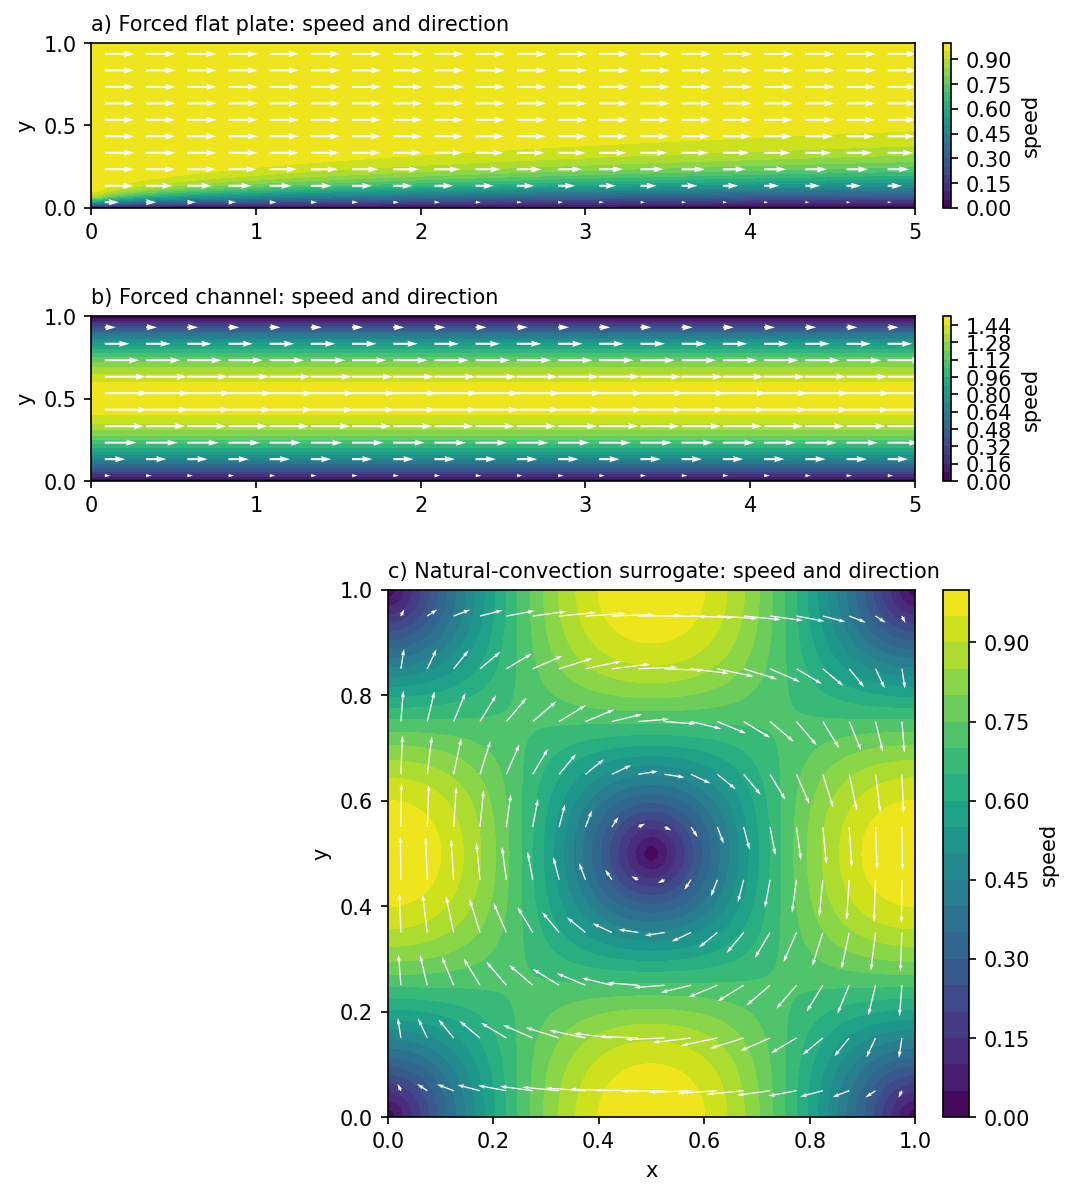

In [18]:
fig = plt.figure(figsize=(12, 9.3))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 3.2], hspace=0.38)
for k, name in enumerate(CASES):
    ax = fig.add_subplot(gs[k]); c = base[name]
    sp = np.sqrt(c["u"] ** 2 + c["v"] ** 2)
    im = ax.contourf(c["X"], c["Y"], sp, levels=20, cmap="viridis")
    st = (slice(2, None, 6), slice(2, None, 6)) if name != "natural_plate" else (slice(3, None, 6), slice(3, None, 6))
    ax.quiver(c["X"][st], c["Y"][st], c["u"][st], c["v"][st], color="w", width=0.0025, scale=28 if name != "natural_plate" else 12)
    ax.set_aspect("equal"); ax.set_title(f"{chr(97 + k)}) {LABEL[name]}: speed and direction", loc="left", fontsize=10)
    ax.set_ylabel("y"); ax.grid(False)
    if k == 2: ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, label="speed", fraction=0.025, pad=0.02)
show(fig, "fig04_velocity_fields")

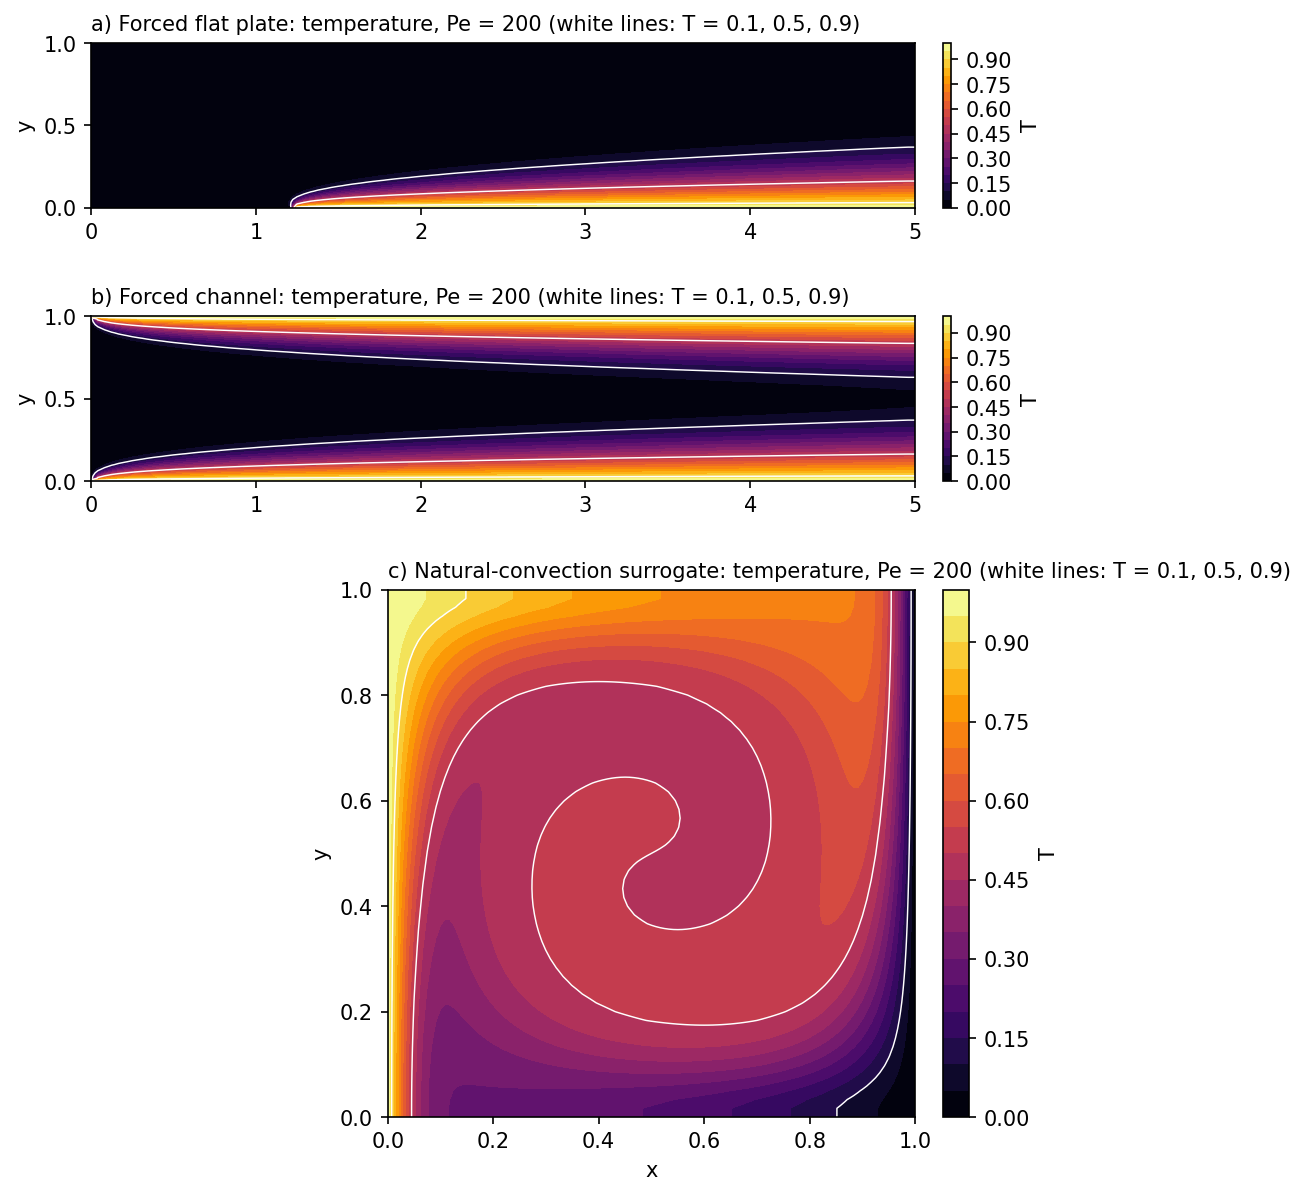

In [19]:
fig = plt.figure(figsize=(12, 9.3))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 3.2], hspace=0.38)
lv = np.linspace(0, 1, 21)
for k, name in enumerate(CASES):
    ax = fig.add_subplot(gs[k]); c = base[name]
    im = ax.contourf(c["X"], c["Y"], c["T"], levels=lv, cmap="inferno")
    ax.contour(c["X"], c["Y"], c["T"], levels=[0.1, 0.5, 0.9], colors="w", linewidths=0.7)
    ax.set_aspect("equal"); ax.set_title(f"{chr(97 + k)}) {LABEL[name]}: temperature, Pe = 200 (white lines: T = 0.1, 0.5, 0.9)", loc="left", fontsize=10)
    ax.set_ylabel("y"); ax.grid(False)
    if k == 2: ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, label="T", fraction=0.025, pad=0.02)
show(fig, "fig05_temperature_fields")

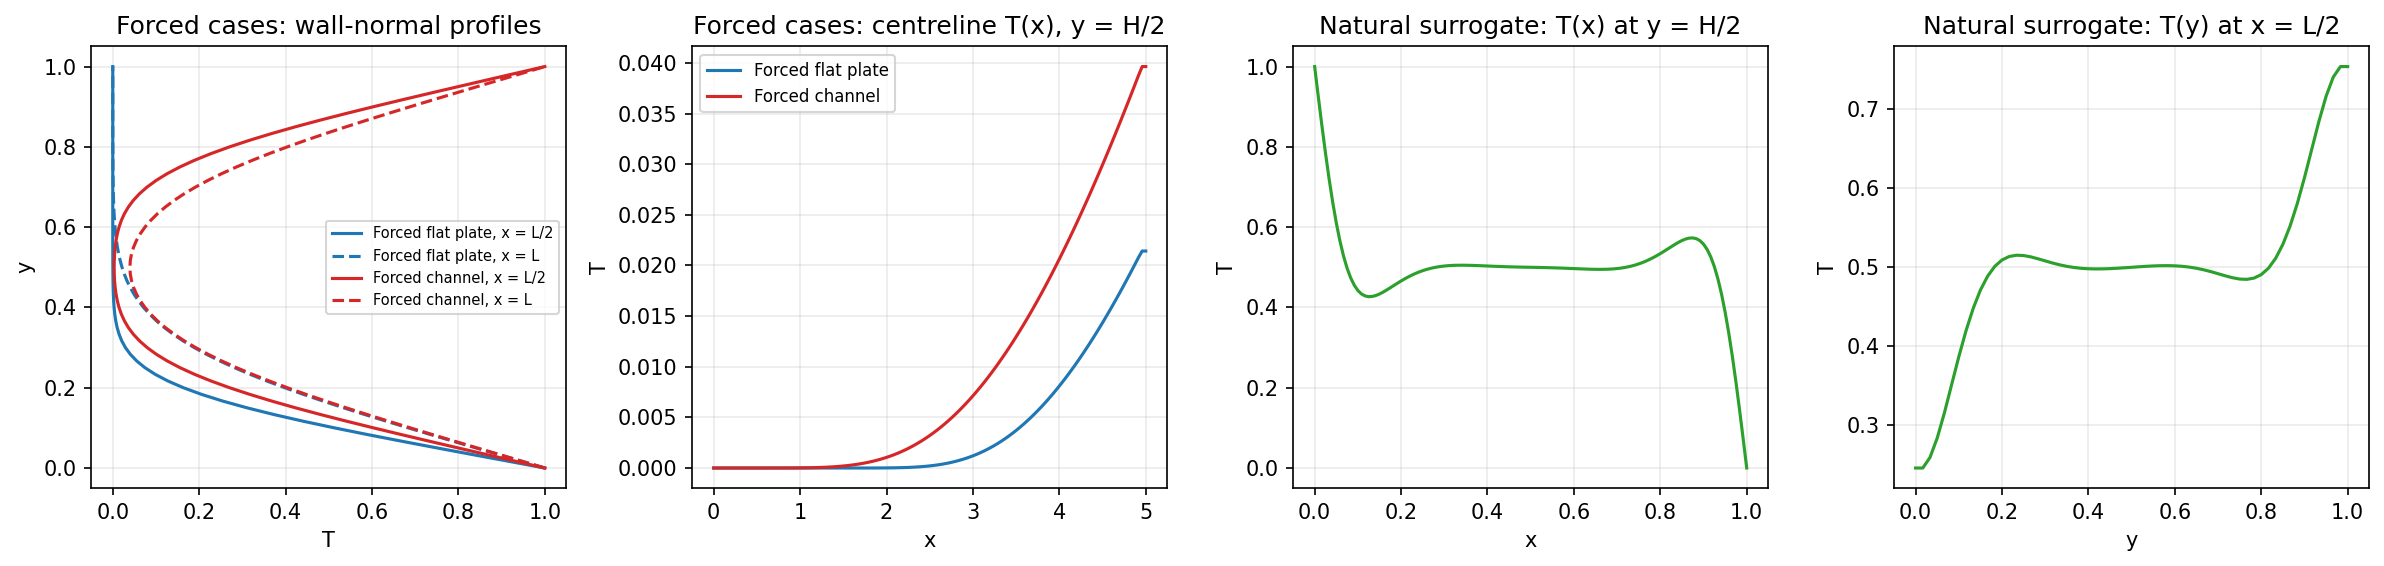

In [20]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9))
for name, col in (("forced_plate", "C0"), ("forced_pipe", "C3")):
    c = base[name]; im = c["nx"] // 2
    axs[0].plot(c["T"][:, im], c["Y"][:, 0], color=col, label=f"{LABEL[name]}, x = L/2")
    axs[0].plot(c["T"][:, -1], c["Y"][:, 0], color=col, ls="--", label=f"{LABEL[name]}, x = L")
axs[0].set(xlabel="T", ylabel="y", title="Forced cases: wall-normal profiles"); axs[0].legend(fontsize=7)
for name, col in (("forced_plate", "C0"), ("forced_pipe", "C3")):
    c = base[name]; jm = c["ny"] // 2
    axs[1].plot(c["X"][0], c["T"][jm, :], color=col, label=LABEL[name])
axs[1].set(xlabel="x", ylabel="T", title="Forced cases: centreline T(x), y = H/2"); axs[1].legend(fontsize=8)
c = base["natural_plate"]
axs[2].plot(c["X"][0], c["T"][c["ny"] // 2, :], "C2")
axs[2].set(xlabel="x", ylabel="T", title="Natural surrogate: T(x) at y = H/2")
axs[3].plot(c["Y"][:, 0], c["T"][:, c["nx"] // 2], "C2")
axs[3].set(xlabel="y", ylabel="T", title="Natural surrogate: T(y) at x = L/2")
fig.tight_layout(); show(fig, "fig06_profiles")

**Figure 6.** Wall-normal and streamwise temperature profiles.

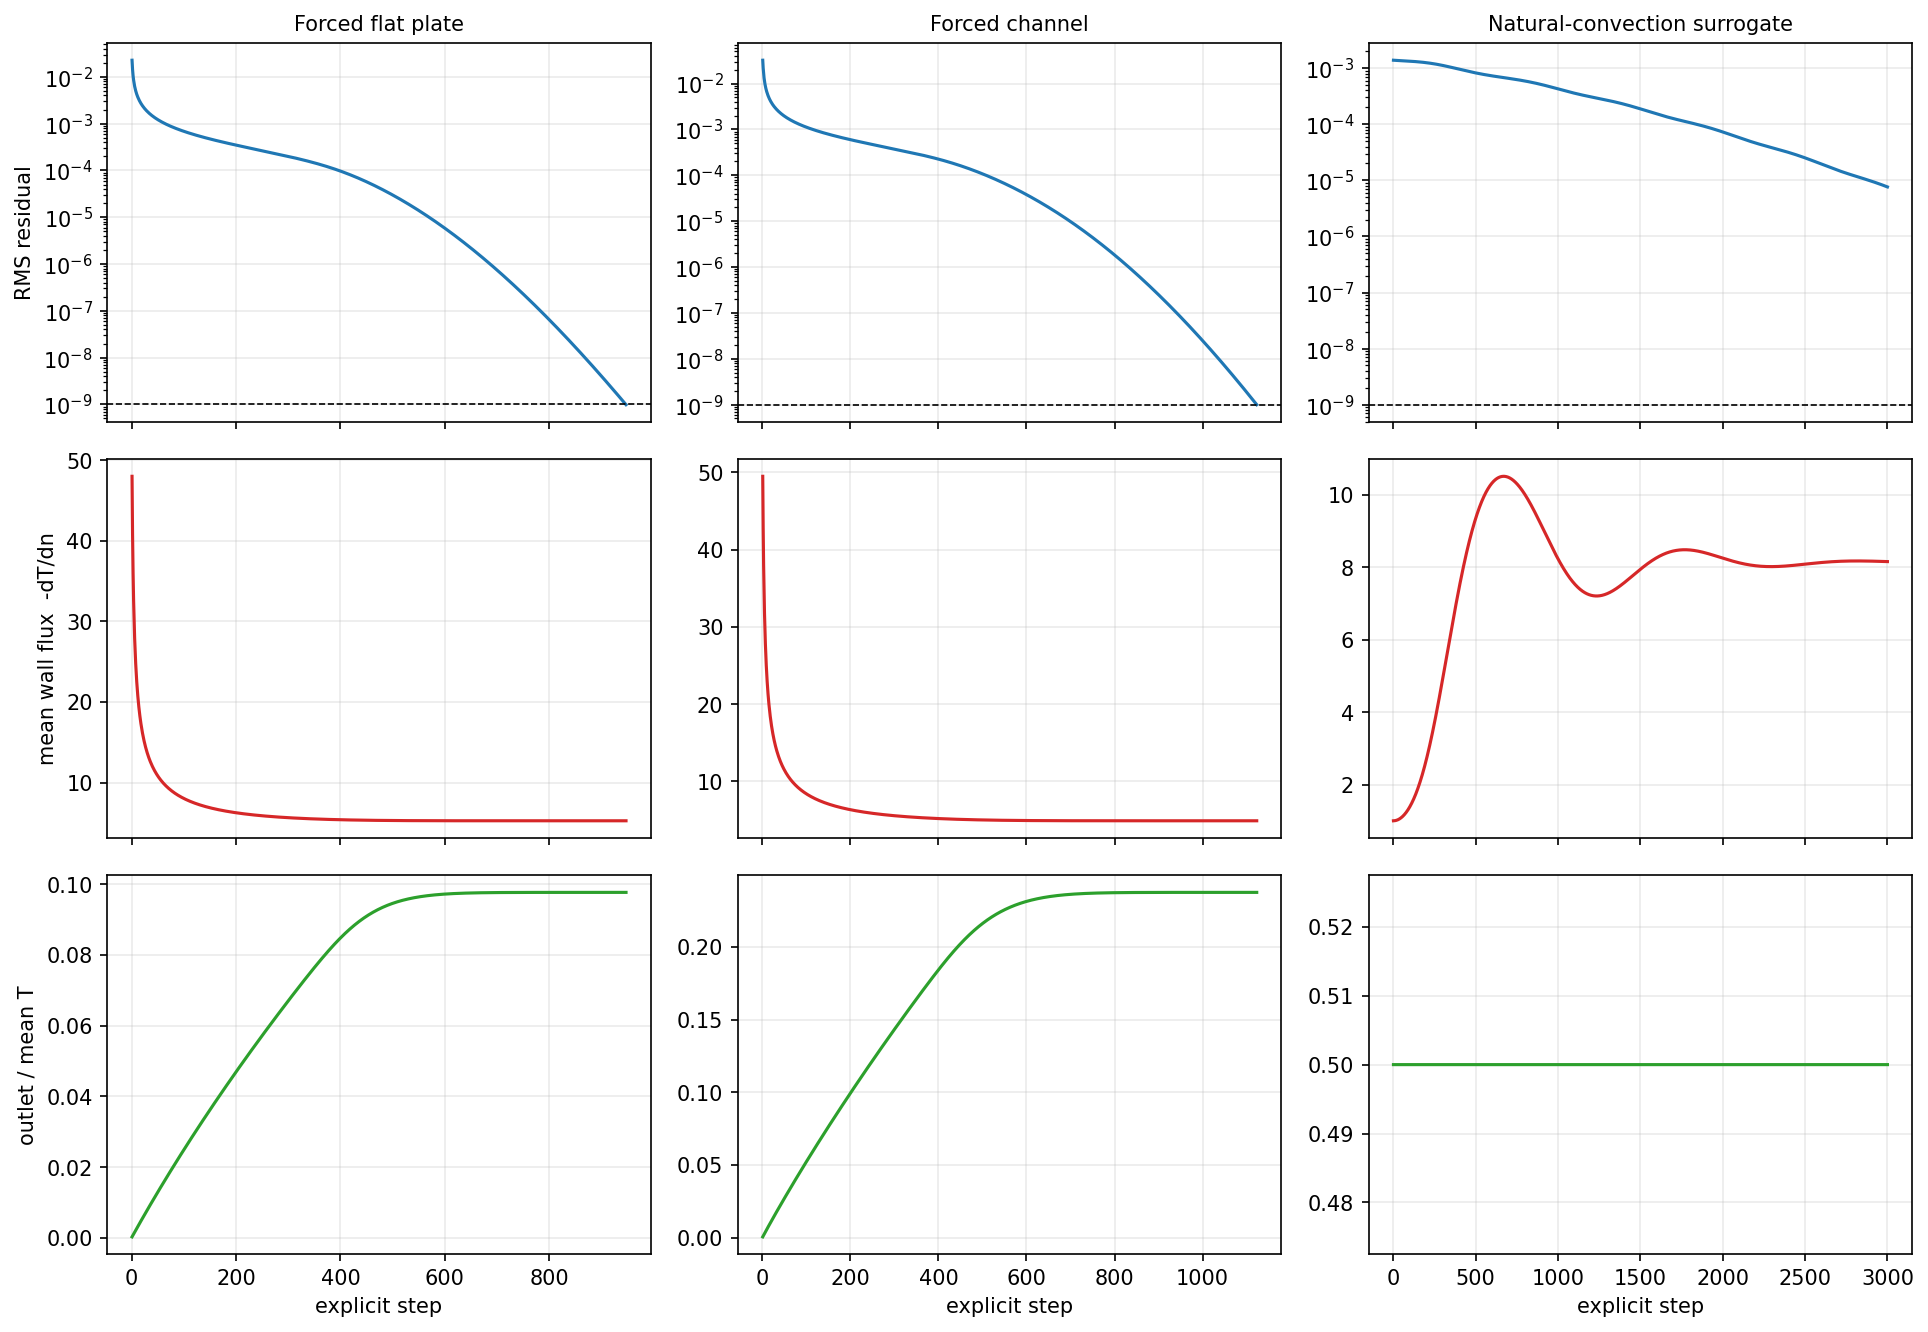

In [21]:
fig, axs = plt.subplots(3, 3, figsize=(13, 9), sharex="col")
for j, name in enumerate(CASES):
    h = base[name]["history"]
    axs[0, j].semilogy(h[:, 0], h[:, 1], "C0"); axs[0, j].axhline(1e-9, color="k", ls="--", lw=0.8)
    axs[1, j].plot(h[:, 0], h[:, 3], "C3"); axs[2, j].plot(h[:, 0], h[:, 2], "C2")
    axs[0, j].set_title(LABEL[name], fontsize=10)
axs[0, 0].set_ylabel("RMS residual"); axs[1, 0].set_ylabel("mean wall flux  -dT/dn"); axs[2, 0].set_ylabel("outlet / mean T")
for ax in axs[2]: ax.set_xlabel("explicit step")
fig.tight_layout(); show(fig, "fig07_convergence_baseline")

In [22]:
scan_df = pd.DataFrame([metrics(runs[(n, pe)]) for pe in PE_LIST for n in CASES])
fits = {}
for n in CASES:
    s = scan_df[scan_df.case == n]
    fits[n] = dict(flux_exponent=float(np.polyfit(np.log(s.Pe), np.log(s.wall_flux), 1)[0]),
                   delta50_exponent=float(np.polyfit(np.log(s.Pe), np.log(s.delta50), 1)[0]))
fit_df = pd.DataFrame(fits).T
display(scan_df[["case", "Pe", "dt", "steps", "converged", "residual", "outlet_or_mean_T", "wall_flux", "delta50", "cellPe_x", "cellPe_y"]])
print("Least-squares power-law exponents over Pe = 50, 200, 1000   (quantity ~ Pe^exponent):")
fit_df

,case,Pe,dt,steps,converged,residual,outlet_or_mean_T,wall_flux,delta50,cellPe_x,cellPe_y
0,forced_plate,50,0.00277778,2834,True,9.9545e-10,0.240334,3.18616,0.17567,2.08333,0
1,forced_pipe,50,0.00277778,2722,True,9.90325e-10,0.564411,3.00667,0.215602,3.125,0
2,natural_plate,50,0.000694444,3000,False,5.58952e-05,0.5,4.5411,0.129099,0.416667,0.833333
3,forced_plate,200,0.0111111,947,True,9.85704e-10,0.0976532,5.25893,0.102973,8.33333,0
4,forced_pipe,200,0.00972222,1123,True,9.97819e-10,0.23741,4.88664,0.127943,12.5,0
5,natural_plate,200,0.00277778,3000,False,7.62234e-06,0.5,8.15148,0.07448,1.66667,3.33333
6,forced_plate,1000,0.0145833,1131,True,9.87724e-10,0.0329386,9.17141,0.0581249,41.6667,0
7,forced_pipe,1000,0.00972222,1792,True,9.97589e-10,0.0827805,8.39351,0.0730452,62.5,0
8,natural_plate,1000,0.00291667,3000,False,3.36264e-05,0.5,16.8565,0.0351953,8.33333,16.6667


Least-squares power-law exponents over Pe = 50, 200, 1000   (quantity ~ Pe^exponent):


,flux_exponent,delta50_exponent
forced_plate,0.352731,-0.368826
forced_pipe,0.342521,-0.360952
natural_plate,0.438174,-0.434688


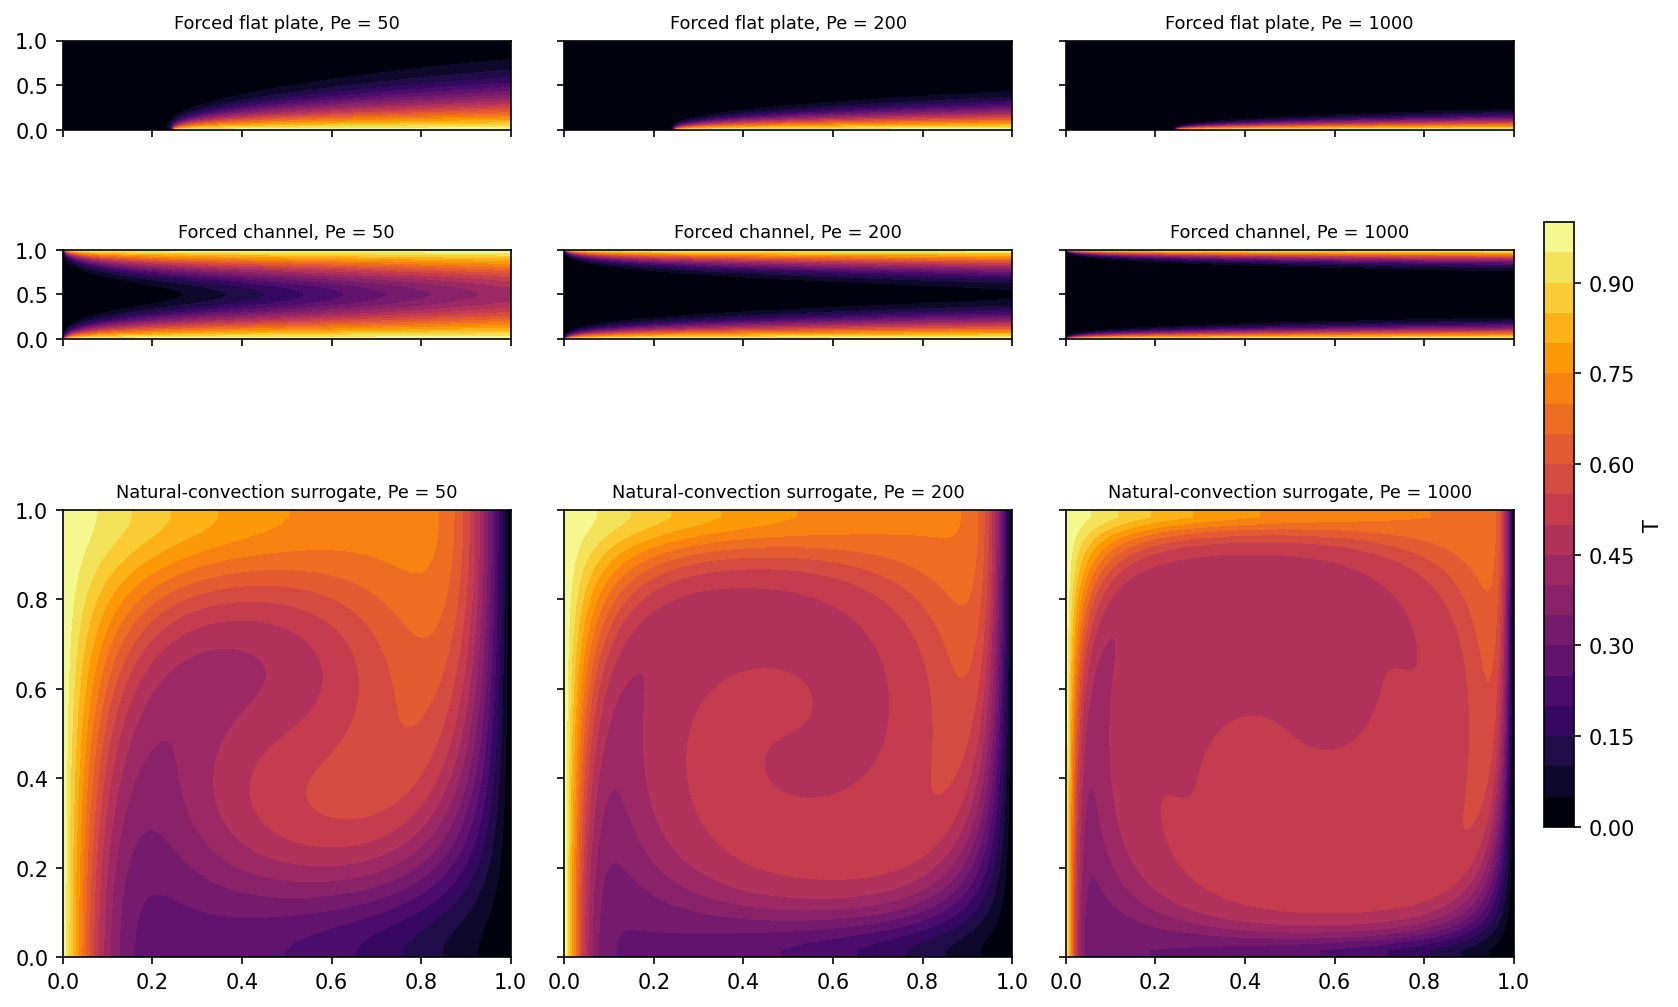

In [23]:
fig = plt.figure(figsize=(13, 8.6))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 5], hspace=0.35, wspace=0.12)
lv = np.linspace(0, 1, 21)
for i, name in enumerate(CASES):
    for j, pe in enumerate(PE_LIST):
        ax = fig.add_subplot(gs[i, j]); c = runs[(name, pe)]
        im = ax.contourf(c["X"], c["Y"], c["T"], levels=lv, cmap="inferno")
        ax.set_aspect("equal"); ax.grid(False)
        ax.set_title(f"{LABEL[name].split(' (')[0]}, Pe = {pe}", fontsize=8.5)
        if j > 0: ax.set_yticklabels([])
        if i < 2: ax.set_xticklabels([])
fig.colorbar(im, ax=fig.axes, label="T", fraction=0.02, pad=0.02)
show(fig, "fig08_pe_scan_fields")

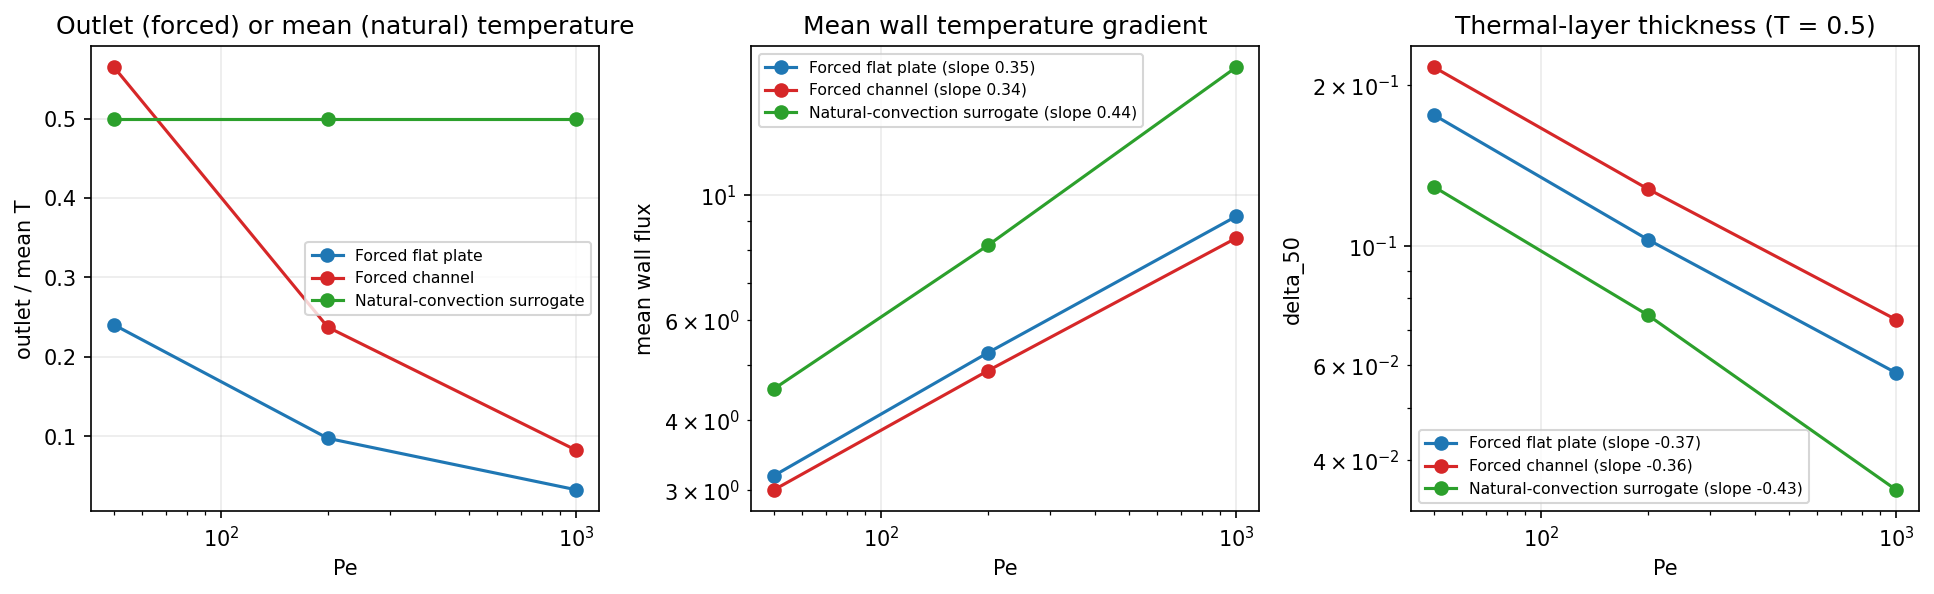

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.1))
cols = {"forced_plate": "C0", "forced_pipe": "C3", "natural_plate": "C2"}
for n in CASES:
    s = scan_df[scan_df.case == n]
    axs[0].semilogx(s.Pe, s.outlet_or_mean_T, "o-", color=cols[n], label=LABEL[n].split(" (")[0])
    axs[1].loglog(s.Pe, s.wall_flux, "o-", color=cols[n], label=f"{LABEL[n].split(' (')[0]} (slope {fits[n]['flux_exponent']:.2f})")
    axs[2].loglog(s.Pe, s.delta50, "o-", color=cols[n], label=f"{LABEL[n].split(' (')[0]} (slope {fits[n]['delta50_exponent']:.2f})")
axs[0].set(xlabel="Pe", ylabel="outlet / mean T", title="Outlet (forced) or mean (natural) temperature")
axs[1].set(xlabel="Pe", ylabel="mean wall flux", title="Mean wall temperature gradient")
axs[2].set(xlabel="Pe", ylabel="delta_50", title="Thermal-layer thickness (T = 0.5)")
for ax in axs: ax.legend(fontsize=7.5)
fig.tight_layout(); show(fig, "fig09_pe_scan_metrics")

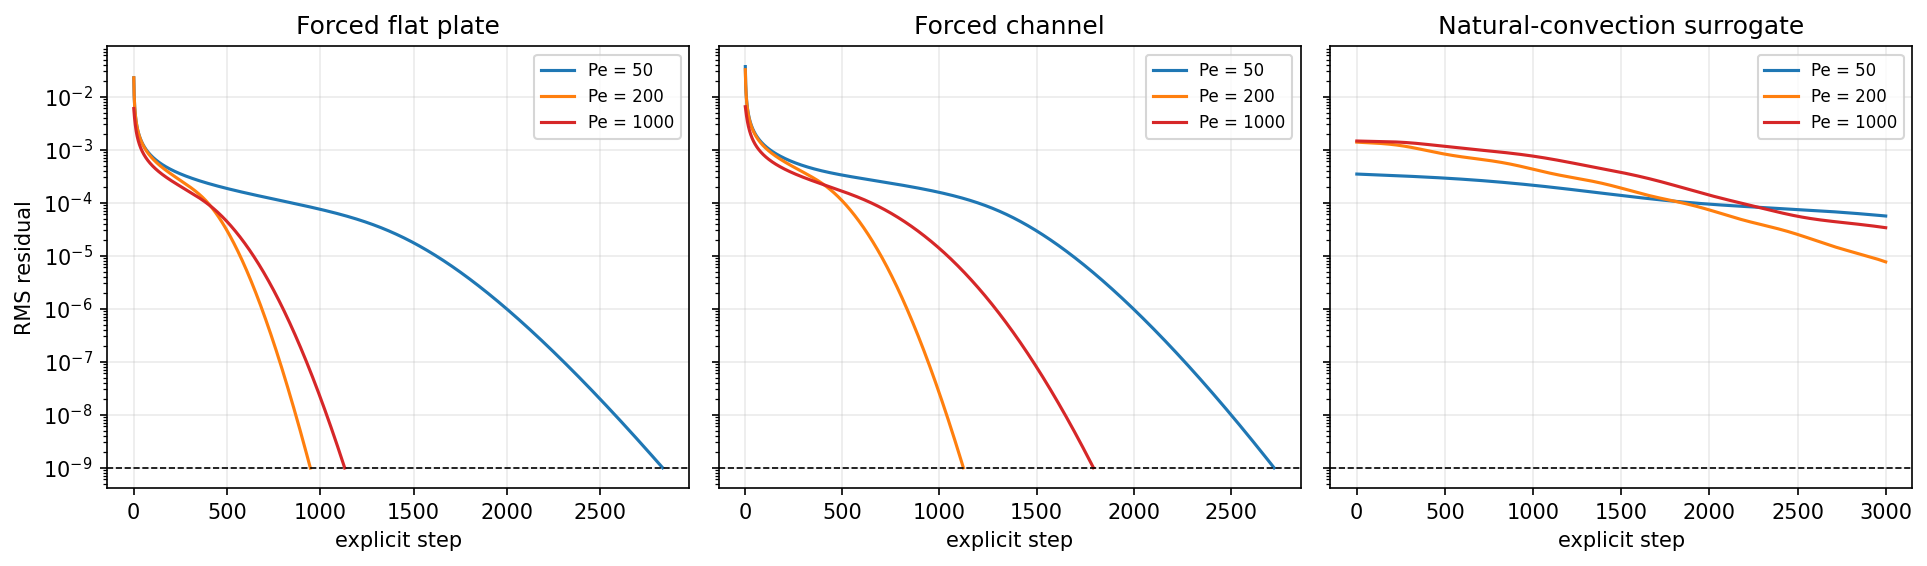

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, n in zip(axs, CASES):
    for pe, col in zip(PE_LIST, ("C0", "C1", "C3")):
        h = runs[(n, pe)]["history"]
        ax.semilogy(h[:, 0], h[:, 1], color=col, label=f"Pe = {pe}")
    ax.axhline(1e-9, color="k", ls="--", lw=0.8); ax.set(xlabel="explicit step", title=LABEL[n].split(" (")[0]); ax.legend(fontsize=8)
axs[0].set_ylabel("RMS residual")
fig.tight_layout(); show(fig, "fig10_pe_scan_residuals")

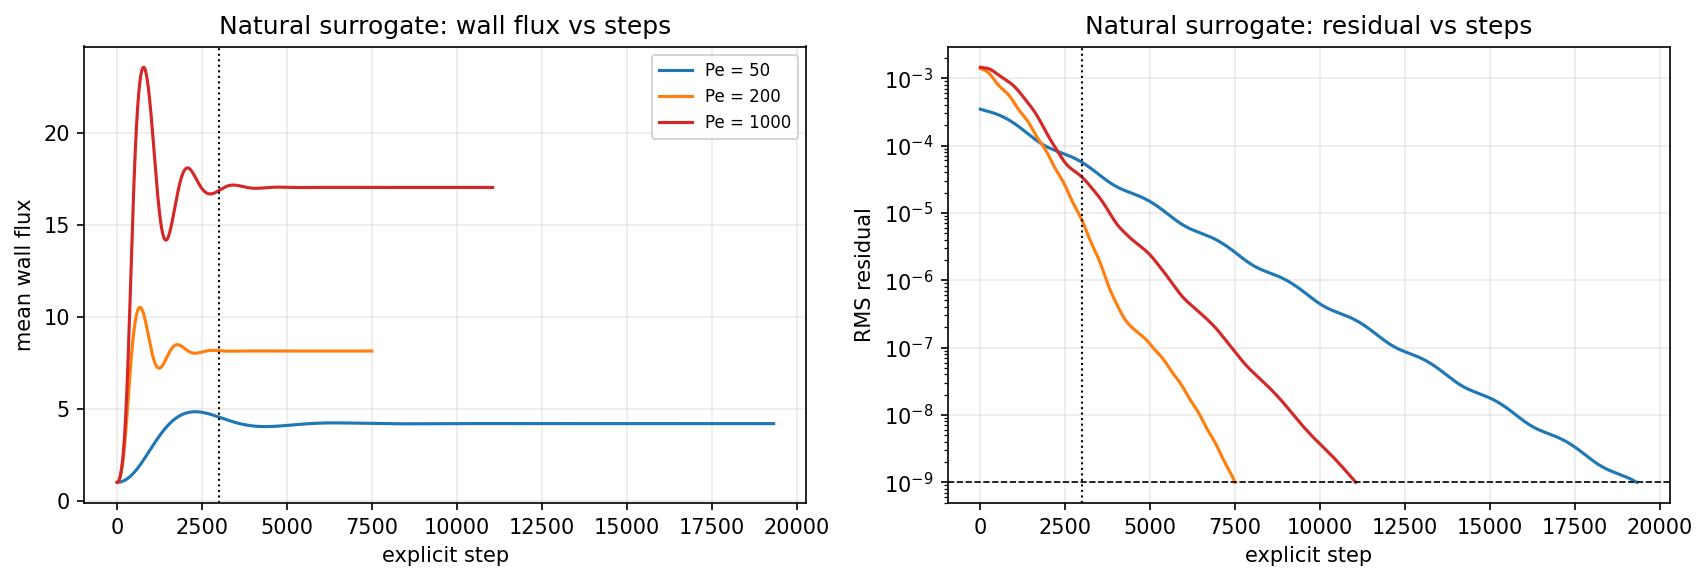

,Pe,flux_at_3000_steps,steps_to_converge,converged,flux_converged,change_pct,delta50_converged,residual
0,50,4.5411,19326,True,4.18832,8.42288,0.147732,9.9938e-10
1,200,8.15148,7497,True,8.13217,0.237539,0.074655,9.98325e-10
2,1000,16.8565,11052,True,17.0181,-0.949709,0.0346529,9.99141e-10


In [26]:
nat_rows, nat_hist = [], {}
for pe in PE_LIST:
    cl = solve(build_case("natural_plate", NX, NY, float(pe)), 150000)
    nat_hist[pe] = cl["history"]
    s3000 = runs[("natural_plate", pe)]["history"][-1]
    nat_rows.append(dict(Pe=pe, flux_at_3000_steps=s3000[3], steps_to_converge=cl["iterations"], converged=cl["converged"],
                         flux_converged=cl["history"][-1][3], change_pct=100 * (s3000[3] / cl["history"][-1][3] - 1),
                         delta50_converged=thickness(cl), residual=cl["residual"]))
nat_df = pd.DataFrame(nat_rows)
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4))
for pe, col in zip(PE_LIST, ("C0", "C1", "C3")):
    h = nat_hist[pe]
    a.plot(h[:, 0], h[:, 3], color=col, label=f"Pe = {pe}"); b.semilogy(h[:, 0], h[:, 1], color=col, label=f"Pe = {pe}")
a.axvline(ITER, color="k", ls=":", lw=1); b.axvline(ITER, color="k", ls=":", lw=1)
a.set(xlabel="explicit step", ylabel="mean wall flux", title="Natural surrogate: wall flux vs steps"); a.legend(fontsize=8)
b.set(xlabel="explicit step", ylabel="RMS residual", title="Natural surrogate: residual vs steps"); b.axhline(1e-9, color="k", ls="--", lw=0.8)
fig.tight_layout(); show(fig, "fig11_natural_continuation")
nat_df

,case,nx,ny,dx,dt,steps,converged,outlet_or_mean_T,wall_flux,delta50,energy_imbalance
0,forced_plate,61,31,0.0833333,0.0291667,377,True,0.0980972,5.19535,0.103355,0.00626508
1,forced_plate,121,61,0.0416667,0.0111111,947,True,0.0976532,5.25893,0.102973,0.010769
2,forced_plate,241,121,0.0208333,0.00277778,3695,True,0.0973478,5.30941,0.102737,0.0178774
3,forced_pipe,61,31,0.0833333,0.0194444,583,True,0.235191,4.83368,0.12747,-0.0125238
4,forced_pipe,121,61,0.0416667,0.00972222,1123,True,0.23741,4.88664,0.127943,0.00189444
5,forced_pipe,241,121,0.0208333,0.00277778,3865,True,0.2383,4.94425,0.128122,0.0168888
6,natural_plate,61,31,0.0166667,0.00583333,3348,True,0.5,7.71153,0.0778035,NaN
7,natural_plate,121,61,0.00833333,0.00277778,7497,True,0.5,8.13217,0.074655,NaN
8,natural_plate,241,121,0.00416667,0.000694444,32789,True,0.5,8.33938,0.0736024,NaN


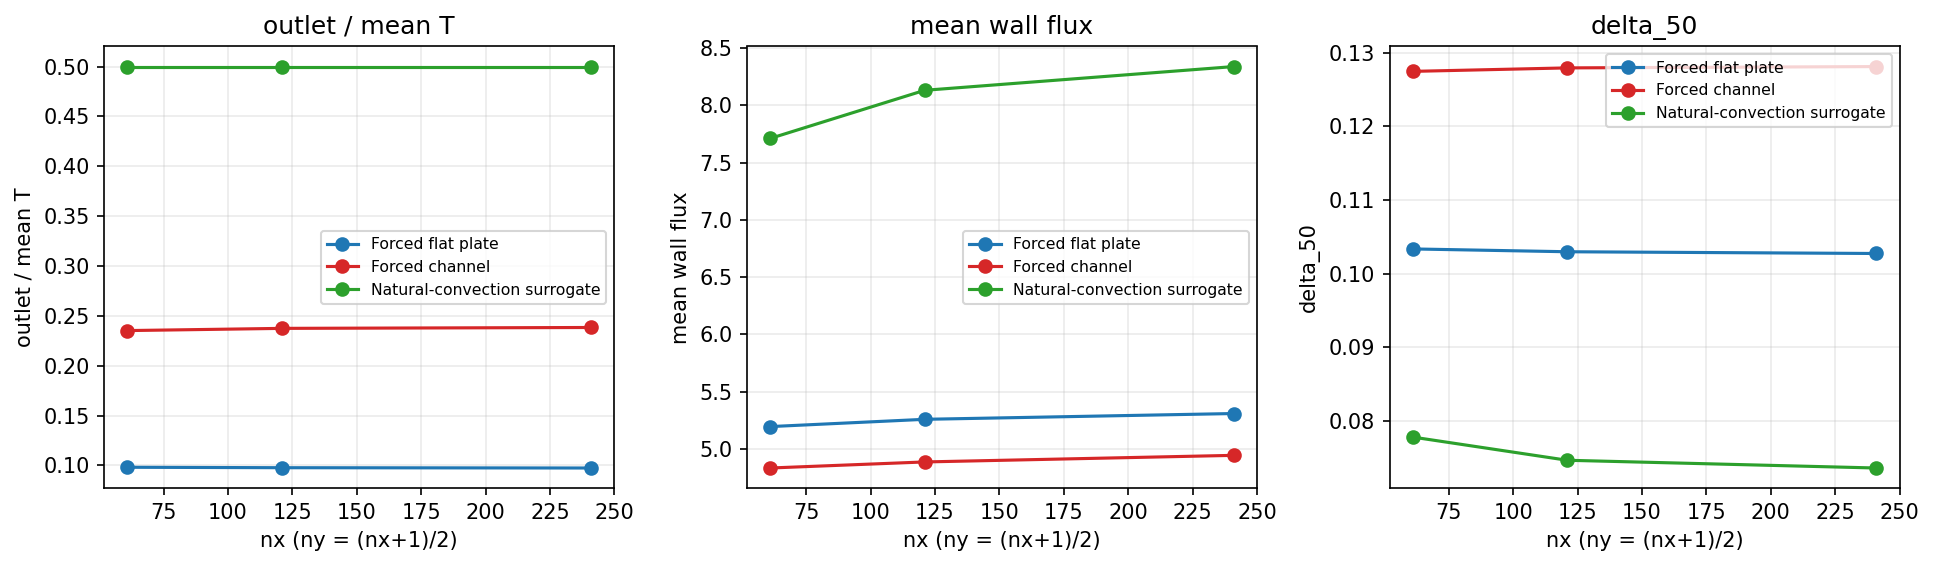

In [27]:
grid_rows = []
for name in CASES:
    dt0 = time_step(build_case(name, 121, 61, PE_BASE))
    for nx_, ny_ in ((61, 31), (121, 61), (241, 121)):
        c0 = build_case(name, nx_, ny_, PE_BASE)
        sc = time_step(c0) / dt0                    # dt ratio -> same physical end time / same steady-state criterion
        c = solve(c0, int(12000 / sc), tol=1e-9 * sc)
        row = metrics(c)
        row["dx"] = c["dx"]
        if name != "natural_plate":
            row["energy_imbalance"] = energy_balance(c)["imbalance_corrected"]
        grid_rows.append(row)
grid_df = pd.DataFrame(grid_rows)[["case", "nx", "ny", "dx", "dt", "steps", "converged", "outlet_or_mean_T", "wall_flux", "delta50"] + ["energy_imbalance"]]
display(grid_df)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
for n in CASES:
    s = grid_df[grid_df.case == n]
    axs[0].plot(s.nx, s.outlet_or_mean_T, "o-", color=cols[n], label=LABEL[n].split(" (")[0])
    axs[1].plot(s.nx, s.wall_flux, "o-", color=cols[n], label=LABEL[n].split(" (")[0])
    axs[2].plot(s.nx, s.delta50, "o-", color=cols[n], label=LABEL[n].split(" (")[0])
for ax, t in zip(axs, ("outlet / mean T", "mean wall flux", "delta_50")):
    ax.set(xlabel="nx (ny = (nx+1)/2)", ylabel=t, title=t); ax.legend(fontsize=7.5)
fig.tight_layout(); show(fig, "fig12_grid_study")